In [3]:

import numpy as np


def kl_residual_nmf(
    X,
    n_components=None,
    *,
    W_init=None,
    H_init=None,
    normalize_W=True,
    update="both",
    max_iter=300,
    tol=1e-5,
    eps=1e-10,
    max_backtracking=40,
    random_state=None,
    verbose=False,
):
    """
    NMF minimizing the squared Frobenius norm of the element-wise
    generalized KL-divergence residual.

    Objective
    ---------
        min 0.5 * ||X * log(X / (W @ H))
                      - X + W @ H||_F^2

    Subject to
    ----------
        W >= 0
        H >= 0

    Parameters
    ----------
    X : ndarray, shape (n_features, n_frames)
        Nonnegative input matrix.

    n_components : int, optional
        Number of components. Can be inferred from initial matrices.

    W_init : ndarray, optional
        Initial basis matrix, shape (n_features, n_components).

    H_init : ndarray, optional
        Initial activation matrix, shape (n_components, n_frames).

    update : {'both', 'W', 'H'}
        'both': optimize W and H alternately.
        'W': optimize W while keeping H fixed.
        'H': optimize H while keeping W fixed.

    max_iter : int
        Maximum number of outer iterations.

    tol : float
        Relative objective-change stopping tolerance.

    eps : float
        Numerical stabilization constant. Also added to W @ H
        when evaluating the divergence.

    max_backtracking : int
        Maximum line-search attempts per block update.

    random_state : int, optional
        Random seed.

    verbose : bool
        Print iteration information.

    Returns
    -------
    W : ndarray
        Learned basis matrix.

    H : ndarray
        Learned activation matrix.

    history : list of dict
        Objective, divergence and update information.
    """
    def project_simplex_columns(A):
        """
        Euclidean projection of each column onto:
            {x >= 0 : sum(x) = 1}
        """
        U = np.sort(A, axis=0)[::-1]
        cssv = np.cumsum(U, axis=0) - 1.0

        indices = np.arange(1, A.shape[0] + 1)[:, None]

        condition = U - cssv / indices > 0
        rho = condition.sum(axis=0) - 1

        theta = (
            cssv[rho, np.arange(A.shape[1])]
            / (rho + 1)
        )

        return np.maximum(A - theta[None, :], 0.0)
    def evaluate(W, H, need_gradient=False):

            Y = W @ H + eps

            positive = X > 0

            E = Y.copy()

            # E = X * log(X/Y) - X + Y.
            E[positive] = (
                X[positive] * np.log(X[positive] / Y[positive])
                - X[positive]
                + Y[positive]
            )

            # Protect against tiny negative round-off errors.
            np.maximum(E, 0.0, out=E)

            objective = 0.5 * np.sum(E * E)

            if not need_gradient:
                return objective

            # Gradient with respect to Y.
            G = E * (1.0 - X / Y)

            # Curvature with respect to Y.
            curvature = (
                (1.0 - X / Y) ** 2
                + E * X / (Y * Y)
            )

            return objective, G, float(np.max(curvature))

    # ---------------------------------------------------------
    # Validation
    # ---------------------------------------------------------
    X = np.asarray(X, dtype=np.float64)

    if X.ndim != 2 or min(X.shape) == 0:
        raise ValueError("X must be a non-empty 2D matrix.")

    if not np.all(np.isfinite(X)) or np.any(X < 0):
        raise ValueError("X must be finite and nonnegative.")

    if update not in {"both", "W", "H"}:
        raise ValueError("update must be 'both', 'W', or 'H'.")

    if max_iter < 1 or max_backtracking < 1:
        raise ValueError("Iteration limits must be positive.")

    if tol < 0 or eps <= 0:
        raise ValueError("tol must be nonnegative and eps positive.")

    F, T = X.shape

    # ---------------------------------------------------------
    # Infer rank
    # ---------------------------------------------------------

    inferred = []

    if W_init is not None:
        W_init = np.asarray(W_init, dtype=np.float64)

        if W_init.ndim != 2:
            raise ValueError("W_init must be 2D.")

        inferred.append(W_init.shape[1])

    if H_init is not None:
        H_init = np.asarray(H_init, dtype=np.float64)

        if H_init.ndim != 2:
            raise ValueError("H_init must be 2D.")

        inferred.append(H_init.shape[0])

    if n_components is None:
        if not inferred:
            raise ValueError(
                "Specify n_components or provide W_init/H_init."
            )
        n_components = inferred[0]

    if not isinstance(n_components, (int, np.integer)) \
            or n_components <= 0:
        raise ValueError("n_components must be positive.")

    K = int(n_components)

    if any(k != K for k in inferred):
        raise ValueError("Initialization matrices have incompatible ranks.")

    rng = np.random.default_rng(random_state)

    # ---------------------------------------------------------
    # Initialize H first
    # ---------------------------------------------------------

    if H_init is not None:
        H = np.asarray(H_init, dtype=np.float64).copy()

        if H.ndim != 2 or not np.all(np.isfinite(H)):
            raise ValueError("Invalid H_init.")

        if np.any(H < 0):
            raise ValueError("H_init must be nonnegative.")

        if H.shape[1] != T:
            raise ValueError("H_init has an incorrect number of frames.")

        if n_components is not None and H.shape[0] != n_components:
            raise ValueError("H_init has an incorrect component count.")

        K = H.shape[0]
    else:
        if update == "W":
            raise ValueError("H_init is required when update='W'.")

        K = int(n_components)
        H = rng.random((K, T)) + eps

    # ---------------------------------------------------------
    # Initialize W
    # ---------------------------------------------------------

    if W_init is not None:
        W = np.asarray(W_init, dtype=np.float64).copy()

        if W.shape != (F, K):
            raise ValueError("W_init has an incorrect shape.")

        if not np.all(np.isfinite(W)) or np.any(W < 0):
            raise ValueError("W_init must be finite and nonnegative.")

    elif update == "W":
        # Ridge-regularized least-squares initialization:
        #
        # W = X H.T (H H.T + ridge I)^(-1)

        HH = H @ H.T
        XH = X @ H.T

        ridge = 1e-8 * max(
            np.trace(HH) / max(K, 1),
            1.0
        )

        W = np.linalg.solve(
            HH + ridge * np.eye(K),
            XH.T
        ).T

        W = np.maximum(W, eps)

    else:
        W = rng.random((F, K)) + eps

    # ---------------------------------------------------------
    # Normalize W if requested
    # ---------------------------------------------------------

    if normalize_W and update in {"both", "W"}:

        W_scale = W.sum(axis=0)

        if np.any(W_scale <= eps):
            raise ValueError("W contains zero columns.")

        W /= W_scale[None, :]

        # Preserve the initial reconstruction only if H is allowed
        # to change.
        if update == "both" and H_init is not None:
            H *= W_scale[:, None]
        # ---------------------------------------------------------
        # Divergence and gradient
        # ---------------------------------------------------------

    # ---------------------------------------------------------
    # Spectral norm squared of a Gram matrix
    # ---------------------------------------------------------

    def spectral_norm_squared(A):

        if A.shape[0] == 0:
            return eps

        eigenvalues = np.linalg.eigvalsh(A)

        return max(float(eigenvalues[-1]), eps)

    # ---------------------------------------------------------
    # Initialize block-specific step sizes
    # ---------------------------------------------------------

    initial_loss, G, curvature_max = evaluate(
        W, H, need_gradient=True
    )

    def spectral_norm_squared(A):
        return max(
            float(np.linalg.eigvalsh(A)[-1]),
            eps
        )

    L_W = spectral_norm_squared(H @ H.T)
    L_H = spectral_norm_squared(W.T @ W)

    # ---------------------------------------------------------
    # Optimization helpers
    # ---------------------------------------------------------

    def update_block(variable, block):

        nonlocal L_W, L_H

        current_loss, G, curvature_max = evaluate(
            W, H, need_gradient=True
        )

        if block == "W":

            gradient = G @ H.T
            gram = H @ H.T
            L = L_W

            old = variable

        else:

            gradient = W.T @ G
            gram = W.T @ W
            L = L_H

            old = variable

        # Improve initial Lipschitz estimate.
        L = max(L, eps)
        accepted = False
        candidate_loss = current_loss

        for bt in range(max_backtracking):

            candidate = old - gradient / L

            if normalize_W:
                candidate = project_simplex_columns(candidate)
            else:
                candidate = np.maximum(candidate, 0.0)

            delta = candidate - old

            delta_norm_sq = np.sum(delta * delta)

            if delta_norm_sq <= eps**2:
                accepted = True
                break

            if block == "W":
                candidate_loss = evaluate(candidate, H)
            else:
                candidate_loss = evaluate(W, candidate)

            # Quadratic majorization condition.
            upper_bound = (
                current_loss
                + np.sum(gradient * delta)
                + 0.5 * L * delta_norm_sq
            )

            tolerance = 1e-12 * max(1.0, abs(current_loss))

            if (
                np.isfinite(candidate_loss)
                and candidate_loss <= upper_bound + tolerance
                and candidate_loss <= current_loss + tolerance
            ):
                accepted = True
                break

            L *= 2.0

        if accepted:

            # Store the accepted step size for the next iteration.
            if block == "W":
                L_W = L
            else:
                L_H = L

            return candidate, True, L, float(candidate_loss)

        return old, False, L, float(current_loss)

    # ---------------------------------------------------------
    # Main optimization loop
    # ---------------------------------------------------------

    history = []
    previous_loss = None

    for iteration in range(1, max_iter + 1):

        W_old = W.copy()
        H_old = H.copy()

        accepted_W = False
        accepted_H = False

        # Update H.
        if update in {"both", "H"}:

            H, accepted_H, L_H, _ = update_block(
                H, "H"
            )

        # Update W.
        if update in {"both", "W"}:

            W, accepted_W, L_W, _ = update_block(
                W, "W"
            )

        # Evaluate complete objective.
        loss = evaluate(W, H)

        divergence = np.sqrt(2.0 * loss)

        relative_change = None

        if previous_loss is not None:

            relative_change = (
                abs(previous_loss - loss)
                / max(abs(previous_loss), eps)
            )

        W_change = np.linalg.norm(W - W_old)
        H_change = np.linalg.norm(H - H_old)

        history.append({
            "iteration": iteration,
            "objective": loss,
            "divergence": divergence,
            "relative_change": relative_change,
            "W_change": W_change,
            "H_change": H_change,
            "W_step_size": L_W,
            "H_step_size": L_H,
            "W_updated": accepted_W,
            "H_updated": accepted_H,
        })

        if verbose:
            print(
                f"Iter {iteration:4d}/{max_iter} | "
                f"D={divergence:.6e} | "
                f"J={loss:.6e} | "
                f"rel={relative_change if relative_change is not None else np.nan:.3e} | "
                f"dW={W_change:.3e} | "
                f"dH={H_change:.3e}"
            )

        if (
            previous_loss is not None
            and relative_change < tol
        ):
            break

        previous_loss = loss

    return W, H, history


In [4]:
pip install pretty_midi

In [5]:
import pretty_midi
def midi_to_cqt_labels(
    midi_input,
    n_frames,
    sr,
    hop_length,
    pitch_range=(21, 108),
    mode="binary"
):
    """
    Generate MIDI ground-truth labels at CQT frame centers.

    Parameters
    ----------
    midi_input : str or pretty_midi.PrettyMIDI
        MIDI file path or loaded MIDI object.
    n_frames : int
        Number of CQT frames.
    sr : int
        Sampling rate.
    hop_length : int
        CQT hop length.
    pitch_range : tuple
        Minimum and maximum MIDI pitches, inclusive.
    mode : str
        "binary"     -> values {0, 1}
        "normalized" -> values {0, 1/128, ..., 1}

    Returns
    -------
    B : ndarray, shape (n_pitches, n_frames)
        Piano roll.
    """

    if mode not in ("binary", "normalized"):
        raise ValueError(
            "mode must be either 'binary' or 'normalized'"
        )

    if isinstance(midi_input, str):
        midi = pretty_midi.PrettyMIDI(midi_input)
    else:
        midi = midi_input

    dt = hop_length / sr

    # CQT frame center timestamps
    times = np.arange(n_frames) * dt

    pitches = np.arange(
        pitch_range[0],
        pitch_range[1] + 1
    )

    dtype = np.uint8 if mode == "binary" else np.float32

    B = np.zeros(
        (len(pitches), n_frames),
        dtype=dtype
    )

    for instrument in midi.instruments:

        for note in instrument.notes:

            if note.pitch not in pitches:
                continue

            pitch_idx = note.pitch - pitch_range[0]

            active = (
                (times >= note.start) &
                (times < note.end)
            )

            if mode == "binary":
                B[pitch_idx, active] = 1

            else:
                velocity = note.velocity / 128.0

                B[pitch_idx, active] = np.maximum(
                    B[pitch_idx, active],
                    velocity
                )

    return B


In [6]:
import librosa
from scipy.io import wavfile
K = 5
L = 0
g = 3
HOP = 2048
file_name_string_audio = "Prelude-in-E-Minor-Nr-4.wav"
def norm_log(H, gamma=5):
    return np.log1p(gamma * H)
f_s, x = wavfile.read(file_name_string_audio)
if(x.dtype==np.int32):
  x = x / (2**31)
elif(x.dtype==np.int16):
  x = x / (2**15)
else:
  raise ValueError(f"Unsupported sample type: {x.dtype}")
spectrogram = np.abs(librosa.cqt(x,sr=f_s, fmin=librosa.note_to_hz('A0'), bins_per_octave=12 * K, n_bins=88 * K+L, hop_length=HOP, sparsity=0.05))
M = midi_to_cqt_labels("Prelude-in-E-Minor-Nr-4.mid", spectrogram.shape[1], 44100, HOP, mode="normalized")
#spectrogram = norm_log(spectrogram, g)
#spectrogram = librosa.util.normalize(spectrogram, norm = 2, axis = 0, threshold = 0.05)


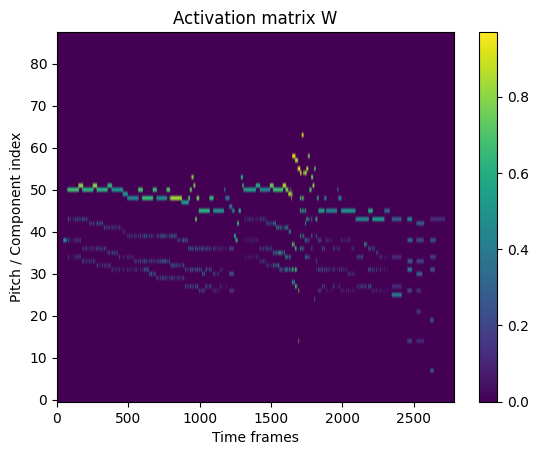

In [7]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(M, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()


In [8]:
print(spectrogram.shape)

(440, 2781)


In [9]:
W, H, history = kl_residual_nmf(
    spectrogram,
    H_init=M,
    update="W",
    normalize_W=False,
    max_iter=200,
    tol=1e-6,
    verbose=True,
)
W_n = W / W.sum(axis=0)

Iter    1/200 | D=6.658333e+02 | J=2.216670e+05 | rel=nan | dW=0.000e+00 | dH=0.000e+00
Iter    2/200 | D=6.648643e+02 | J=2.210223e+05 | rel=2.909e-03 | dW=9.648e-10 | dH=0.000e+00
Iter    3/200 | D=6.646223e+02 | J=2.208614e+05 | rel=7.277e-04 | dW=3.730e-10 | dH=0.000e+00
Iter    4/200 | D=6.644492e+02 | J=2.207464e+05 | rel=5.208e-04 | dW=3.107e-10 | dH=0.000e+00
Iter    5/200 | D=6.643125e+02 | J=2.206556e+05 | rel=4.115e-04 | dW=2.741e-10 | dH=0.000e+00
Iter    6/200 | D=6.641988e+02 | J=2.205800e+05 | rel=3.424e-04 | dW=2.488e-10 | dH=0.000e+00
Iter    7/200 | D=6.641010e+02 | J=2.205151e+05 | rel=2.943e-04 | dW=2.300e-10 | dH=0.000e+00
Iter    8/200 | D=6.640151e+02 | J=2.204581e+05 | rel=2.587e-04 | dW=2.151e-10 | dH=0.000e+00
Iter    9/200 | D=6.639384e+02 | J=2.204071e+05 | rel=2.311e-04 | dW=2.029e-10 | dH=0.000e+00
Iter   10/200 | D=6.638690e+02 | J=2.203610e+05 | rel=2.092e-04 | dW=1.928e-10 | dH=0.000e+00
Iter   11/200 | D=6.638055e+02 | J=2.203189e+05 | rel=1.912e-04 | 

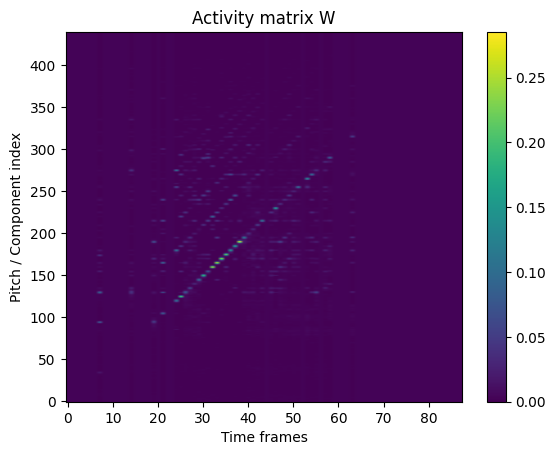

In [10]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W_n, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activity matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [11]:
def nonzero_row_indices(matrix):
    """
    Return indices of rows containing at least one nonzero element.
    """
    matrix = np.asarray(matrix)
    return np.flatnonzero(np.any(matrix != 0, axis=1))
print(nonzero_row_indices(M), len(nonzero_row_indices(M)))

[ 7 14 19 21 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43
 45 46 47 48 49 50 51 53 54 55 57 58 63] 37


In [12]:
import os
import psutil

process = psutil.Process(os.getpid())

def print_memory(stage):
    mem = process.memory_info().rss / (1024**3)
    print(f"[{stage}] RAM usage: {mem:.2f} GB")

In [59]:
from pathlib import Path
import gc

def get_files(extension):
    return [str(file) for file in Path.cwd().rglob("*."+extension)]
def merge_matrices(A, B):
    if A.shape != B.shape:
        raise ValueError("Matrices must have the same shape.")

    mask = ~np.any(A != 0, axis=0)
    A[:, mask] = B[:, mask]

    return A
def compute_columns_list(W_n, t=0.05):
  W_o = np.zeros(W_n.shape)
  l = []
  for i in range(88):
    s = 0
    start = 0 if (i*K-K//2 <= 0) else i*K-K//2
    end = 88*K-1 if (i*K+K//2 >= 88*K-1) else i*K+K//2
    for k in range(start,end+1):
      s += W_n[k,i]
    if(s>t):
      W_o[:,i] = W_n[:,i]
  return W_o

def get_nonzero_rows_indices(A):
    A = np.asarray(A)
    return np.where(np.any(A != 0, axis=1))[0]

def fill_zero_columns(R, K, copy=True):
    """
    Fill zero columns using the nearest nonzero columns.

    A basis vector is shifted by multiples of K bins
    according to the difference between source and target pitches.

    Parameters
    ----------
    R : ndarray, shape (88*K, 88)
        Dictionary matrix.
    K : int
        Number of CQT bins per semitone.
    copy : bool
        Whether to modify a copy of R.

    Returns
    -------
    ndarray
        Dictionary with all columns filled.
    """

    R = np.array(R, copy=copy)

    n_bins, n_pitches = R.shape

    valid = np.where(np.any(R != 0, axis=0))[0]
    missing = np.where(~np.any(R != 0, axis=0))[0]

    if len(valid) == 0:
        raise ValueError("R contains no nonzero columns.")

    for pitch in missing:

        # Find nearest available pitch
        nearest = valid[np.argmin(np.abs(valid - pitch))]

        # Shift the basis vector
        shift = (pitch - nearest) * K

        source = R[:, nearest]

        R[:, pitch] = np.roll(source, shift)

        # Remove wrapped-around values
        if shift > 0:
            R[:shift, pitch] = 0

        elif shift < 0:
            R[shift:, pitch] = 0

    return R


def build_W_from_data(nof_vectors=50, add_vectors=10):
  l = get_files("wav")
  r = get_files("mid")
  R = np.zeros((88*K,88))
  for m in l.copy():
    if(not m[:-3]+"mid" in r):
      l.remove(m)
  l.remove("/content/Prelude-in-E-Minor-Nr-4.wav")
  for file_name_string_audio in l:
    f_s, x = wavfile.read(file_name_string_audio)
    # Normalize audio
    if x.dtype == np.int32:
        x = x.astype(np.float32) / (2**31)

    elif x.dtype == np.int16:
        x = x.astype(np.float32) / (2**15)

    elif x.dtype == np.uint8:
        x = (x.astype(np.float32) - 128) / 128

    elif x.dtype == np.float32:
        x = x.copy()

    elif x.dtype == np.float64:
        x = x.astype(np.float32)

    else:
        raise ValueError(f"Unsupported sample type: {x.dtype}")

    # Convert multichannel audio to mono
    if x.ndim > 1:
        x = np.mean(x, axis=1, dtype=np.float32)
    print("New iteration, number of nonzero R columns: ", len(get_nonzero_rows_indices(R.T)))
    S = np.abs(librosa.cqt(x,sr=f_s, fmin=librosa.note_to_hz('A0'), bins_per_octave=12 * K, n_bins=88 * K+L, hop_length=HOP, sparsity=0.05))
    M = midi_to_cqt_labels(file_name_string_audio[:-3]+"mid", S.shape[1], f_s, HOP, mode="normalized")
    if(len(set(get_nonzero_rows_indices(M))-set(get_nonzero_rows_indices(R.T)))<add_vectors):
      del S, M
      gc.collect()
      print("Skipped iteration: less new columns than add_vectors")
      continue
    W, H, history = kl_residual_nmf(
    S,
    H_init=M,
    update="W",
    normalize_W=False,
    max_iter=200,
    tol=1e-6,
    verbose=False,
    )
    W_n = W / W.sum(axis=0)
    W_f = compute_columns_list(W_n)
    R = merge_matrices(R, W_f)
    R = fill_zero_columns(R, K)
    del x, f_s, S, M, W, H, history, W_n, W_f
    gc.collect()
    if(len(get_nonzero_rows_indices(R.T))>nof_vectors):
      print("Finished: number of vectors bigger than nof_vectors found")
      R = fill_zero_columns(R, K)
      break
  return R


In [60]:
res = build_W_from_data()

/tmp/ipykernel_46826/3410861466.py:100: WavFileWarning: Chunk (non-data) not understood, skipping it.
  f_s, x = wavfile.read(file_name_string_audio)


New iteration, number of nonzero R columns:  0
Finished: number of vectors bigger than nof_vectors found


In [55]:
np.save("res.npy", res)

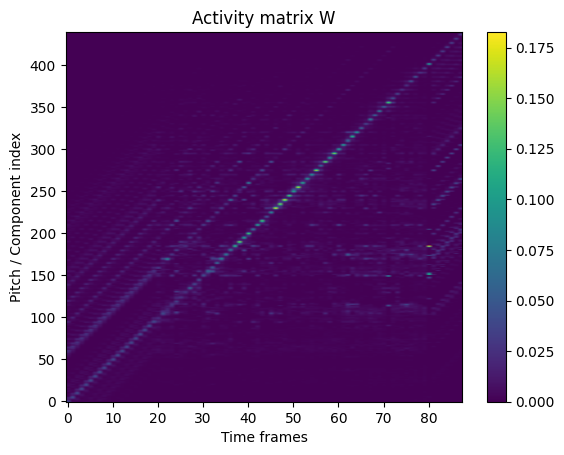

In [61]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(res, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activity matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [29]:
print(get_nonzero_rows_indices(res.T))

[19 20 21 22 23 24 25 26 27 28 30 31 32 33 34 35 36 37 38 39 40 41 42 43
 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67
 68 69 70 71 72 73 74 75 76 77 78 79 80 81]
